# Trained scoring over frozen inputs on quarterly splits

Average historical liked-recipe vectors for each user, then learn user–recipe compatibility.
MiniLM stays frozen; only the scoring layers are trained. Generate inputs once with
`python scripts/embed_recipes.py --device mps`, or `--kind tfidf` for lexical inputs.

`variant`: `baseline` uses joint name/ingredient MiniLM vectors; `softmax` changes the loss;
`separate_fields` concatenates name and ingredient vectors; `tfidf` uses sparse lexical vectors.
`architecture`: `linear` transforms only the user vector; `nonlinear` uses separate linear + ReLU towers.
Scores are dot products. There is no popularity blend or automatic winner/test evaluation.

In [1]:
# Optional if you have trouble running the environment.
import sys
sys.path.insert(0, "../src")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from remy.splits import RollingSplits, SPLIT_DIR
from remy.evaluate import evaluate_quarter
from remy.model.embedding import EmbeddingRecommender, load_embeddings
from remy.model.embedding_trained import TrainedEmbeddingRecommender, training_examples

In [2]:
splits = RollingSplits()
split = "val"
model_kwargs = dict(
    variant="softmax",
    architecture="nonlinear",
    width=128,
    learning_rate=0.001,
    epochs=15,
    batch_size=512,
    seed=10718,
    n_candidates=1000,
)
kind = model_kwargs["variant"] if model_kwargs["variant"] in ["separate_fields", "tfidf"] else "joint"
embeddings = load_embeddings(kind)
eval_quarters = splits.evaluation_quarters(split)
assert len(eval_quarters) == 16
assert np.array_equal(embeddings["id"], splits.recipes.sort_values("id").id.to_numpy())
output = SPLIT_DIR / f"embedding_trained_{model_kwargs['variant']}_{model_kwargs['architecture']}_{split}.csv"

splits.windows.groupby("split", sort=False)[
    ["outcome_reviews", "positive_reviews", "positive_users"]
].sum().rename(columns={"positive_users": "positive_user_quarters"})

,outcome_reviews,positive_reviews,positive_user_quarters
split,,,
train,138126,106422,19880
val,377717,279537,61814
test,134059,100846,29079


## Historical training examples

Each 5-star outcome is paired with five randomly sampled alternatives from the historical top 10k.
Alternatives exclude seen recipes and recipes reviewed during that training quarter.
User profiles use only history before that training quarter (5★=1, 4★=0.5).
TF-IDF vocabulary/IDF are frozen before the earliest training quarter.

Prepare completed quarters once and append each validation quarter only after it ends.
Each evaluation still trains a fresh network. AdamW weight decay is 0.0001; no dropout.
Pairwise loss averages `softplus(negative - positive)`; softmax uses cross-entropy over all six scores.

In [3]:
training_data = [
    training_examples(q, embeddings, seed=model_kwargs["seed"])
    for q in splits.training_quarters(eval_quarters[0].start)
]
assert all(data["end"] <= eval_quarters[0].start for data in training_data)
print("Historical positive examples:", sum(len(data["user_rows"]) for data in training_data))

Historical positive examples: 43136


## Fit and evaluate

Run all 16 validation quarters with the settings above. Results are saved after each quarter.
Current outcomes are used only for scoring, then become history for the next cutoff.

In [4]:
rows = []
total_start = time.perf_counter()
for quarter in eval_quarters:
    quarter_start = time.perf_counter()
    assert (quarter.history.date < quarter.start).all()
    assert (quarter.recipes.submitted < quarter.start).all()
    assert all(data["end"] <= quarter.start for data in training_data)
    model = TrainedEmbeddingRecommender(embeddings=embeddings, **model_kwargs)
    model.fit(quarter.history, recipes=quarter.recipes, training_data=training_data)
    users = quarter.outcomes.loc[quarter.outcomes.rating == 5, "user_id"].unique()
    recs = model.recommend_batch(users)
    assert set(model.candidates_).issubset(set(quarter.recipes.id))
    assert all(not set(ids) & model.seen_.get(user, set()) for user, ids in recs.items())
    rows.append(evaluate_quarter(quarter, model.ranking_, model.seen_, recs))
    pd.DataFrame(rows).to_csv(output, index=False)
    print(f"Finished {quarter.start.date()} in {(time.perf_counter() - quarter_start) / 60:.2f} min "
          f"(total: {(time.perf_counter() - total_start) / 60:.2f} min)")
    if quarter.end < eval_quarters[-1].end:
        training_data.append(training_examples(quarter, embeddings, seed=model_kwargs["seed"]))

results = pd.DataFrame(rows)

epoch 1 loss 1.73029


epoch 2 loss 1.66095


epoch 3 loss 1.61441


epoch 4 loss 1.57154


epoch 5 loss 1.53484


...

epoch 12 loss 1.34221


epoch 13 loss 1.33283


epoch 14 loss 1.32796


epoch 15 loss 1.32236


Finished 2010-10-01 in 0.30 min (total: 4.16 min)


## Results

These are validation results, not test-set estimates. Compare only matching sets of quarters.

In [5]:
metrics = ["NDCG", "HR@10", "HR@100", "Recall@10", "Recall@100", "candidate_recall"]
results[metrics].mean().to_frame("Mean across quarters").round(4)

,Mean across quarters
NDCG,0.1249
HR@10,0.0387
HR@100,0.1651
Recall@10,0.0145
Recall@100,0.0702
candidate_recall,0.1538


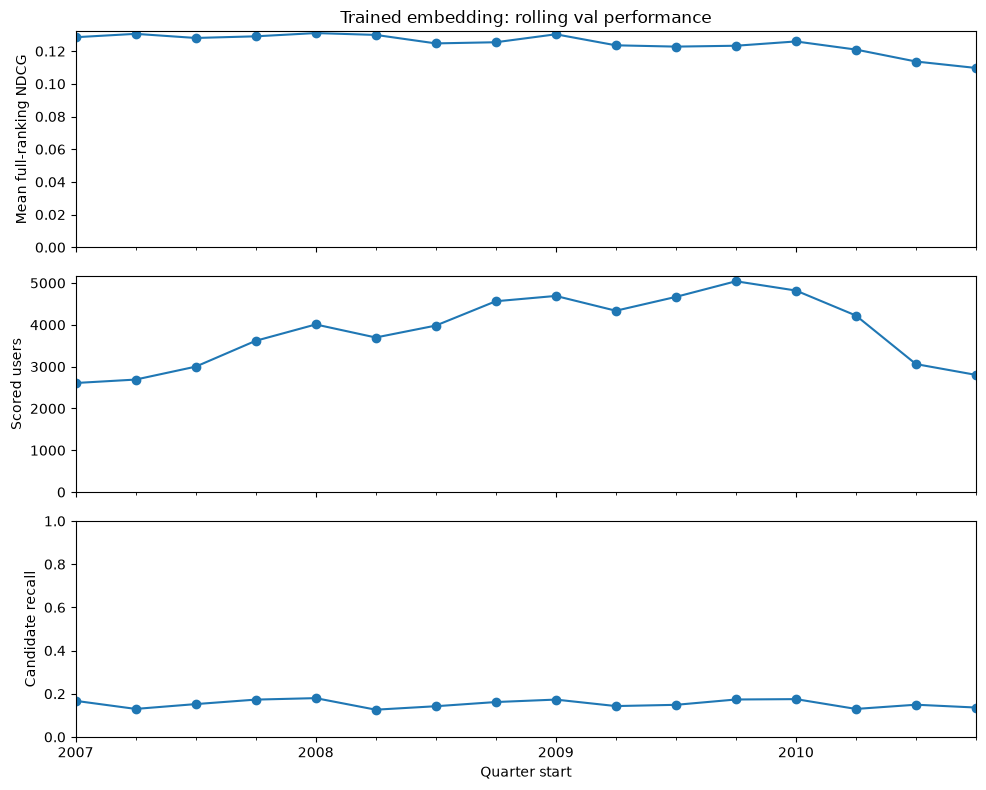

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
results.plot(x="start", y="NDCG", marker="o", legend=False, ax=axes[0])
axes[0].set(title=f"Trained embedding: rolling {split} performance", ylabel="Mean full-ranking NDCG")
axes[0].set_ylim(bottom=0)
results.plot(x="start", y="scored_users", marker="o", legend=False, ax=axes[1])
axes[1].set(ylabel="Scored users")
axes[1].set_ylim(bottom=0)
results.plot(x="start", y="candidate_recall", marker="o", legend=False, ax=axes[2])
axes[2].set(ylabel="Candidate recall", xlabel="Quarter start")
axes[2].set_ylim(0, 1)
fig.tight_layout()
plt.show()